# Notebook 15 — E3 economic routing

**Question.** Does phase-prioritised economic routing improve resource conversion under the same safety layer, and what does it cost in offensive opportunity or safety?

**Additional framing.** With the same multi-step safety layer held fixed, does phase-based coin–crate routing improve resource conversion, and does that benefit come at the cost of offensive opportunities or safety?

## Locked experimental design

- Frozen candidate: `dueling_hunt_center_04`; checkpoint `709cca4351f3bc5893f766b01b8c9335fa299d25331a275ae281b123df31009a`
- Conditions: `no_economic_route`, `coin_only`, `full_economic_route`
- Main lineups: `external_mixed`, `frozen_dddqn`; added robustness lineups: `rule3`, `internal_mixed`
- Fresh seeds: `67001–67040`; 5 rounds per seed
- Workload: 2,400 rounds; no training and zero exploration
- Primary metric: mean score per round
- Prespecified contrasts: full − no-route, and full − coin-only
- Inference: average five rounds within each seed, then paired 10,000-replicate seed-cluster bootstrap

The manipulation is source-selective. `objective_target` is cleared before network inference and before the direct +1.0 Q bonus only for the disabled economic sources. Escape and opponent objectives, the safety mask and hybrid bomb rule, the +0.04 hunt-centre bias, revisit penalty, model weights, and architecture are common to all arms.

In [1]:
from pathlib import Path
import json, pandas as pd
ROOT = Path('..').resolve()
payload = json.loads((ROOT/'results/e3_economic_routing/summary.json').read_text())
extension = json.loads((ROOT/'results/e3_economic_routing_extension/summary.json').read_text())
aggregate = pd.DataFrame(payload['aggregate'] + extension['aggregate'])
paired = pd.DataFrame(payload['paired_bootstrap'] + extension['paired_bootstrap'])
aggregate

,lineup,variant,seed_clusters,rounds,score,coins,crates,bombs,kills,suicides,...,hunt_steps,opponent_activations,coin_distance_reduction,crate_distance_reduction,self_trapped_after_bomb,decision_ms_mean,economic_activation_rate,economic_target_selection_rate,opponent_activation_rate,decision_ms_p95
0,external_mixed,no_economic_route,40,200,2.250,1.275,18.575,40.220,0.195,0.235,...,86.075,40.055,0.799899,0.207001,0.265,5.572564,0.352234,0.531702,0.122206,14.477015
1,external_mixed,coin_only,40,200,2.230,1.480,18.060,38.760,0.150,0.290,...,76.635,36.040,0.942138,0.202498,0.295,6.586552,0.366344,0.552495,0.112061,16.922486
2,external_mixed,full_economic_route,40,200,2.495,1.670,22.990,41.745,0.165,0.185,...,129.315,60.035,0.947561,0.558705,0.180,6.566350,0.279037,0.831919,0.176644,16.927862
3,frozen_dddqn,no_economic_route,40,200,2.685,1.710,24.155,41.880,0.195,0.220,...,142.870,59.065,0.795456,0.224954,0.295,6.930676,0.279508,0.585252,0.165971,18.230247
4,frozen_dddqn,coin_only,40,200,3.380,1.930,23.515,41.280,0.290,0.225,...,139.590,57.675,0.940677,0.212361,0.275,6.866674,0.285010,0.606257,0.162479,18.186271
5,frozen_dddqn,full_economic_route,40,200,3.115,2.115,28.180,39.865,0.200,0.260,...,146.255,60.655,0.947683,0.522589,0.320,6.557908,0.250118,0.863890,0.178471,17.522418
6,rule3,no_economic_route,40,200,3.280,2.330,26.100,40.395,0.190,0.225,...,42.390,19.970,0.797261,0.195598,0.215,11.088152,0.413614,0.567339,0.061579,32.359660
7,rule3,coin_only,40,200,3.895,2.695,25.005,40.960,0.240,0.210,...,44.925,21.195,0.940311,0.177969,0.225,13.965458,0.418902,0.586220,0.063032,40.961635
8,rule3,full_economic_route,40,200,4.275,3.025,30.060,39.915,0.250,0.180,...,87.510,40.575,0.939954,0.537810,0.180,87.553194,0.325804,0.855705,0.124349,44.474363
9,internal_mixed,no_economic_route,40,200,2.495,1.745,25.820,45.515,0.150,0.110,...,152.170,71.995,0.782959,0.234806,0.160,68.708682,0.277978,0.587629,0.193728,39.680898


## Completeness and matched initial conditions

| lineup | matched_rounds | expected |
| --- | --- | --- |
| external_mixed | 200 | 200 |
| frozen_dddqn | 200 | 200 |
| rule3 | 200 | 200 |
| internal_mixed | 200 | 200 |

## Metric definitions

- `economic_activation_rate`: counterfactual coin/crate objective activations divided by all candidate decisions.
- `economic_target_selection_rate`: among those activations, the fraction in which the final selected action belongs to the counterfactual economic target set.
- `coin_distance_reduction` / `crate_distance_reduction`: mean chosen-action progress on activated objectives; positive means one BFS step closer.
- `safe_productive_bombs`: actually placed bombs carrying the frozen extractor's safe-and-crate-productive flag.
- `self_trapped_after_bomb`: an observed state before the agent's own bomb explodes with no legal action having a survivable continuation.

Rates and progress values can differ across arms because disabling routing changes later visited states; they are descriptive mechanism outcomes, not fixed exposure covariates.

## Aggregate results

All count outcomes are means per round; `hunt_steps` is therefore steps per round.

| lineup | variant | rounds | score | coins | crates | bombs | safe_productive_bombs | economic_activation_rate | economic_target_selection_rate | coin_distance_reduction | crate_distance_reduction | kills | hunt_steps | opponent_activation_rate | suicides | invalid | survived | self_trapped_after_bomb | decision_ms_p95 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| external_mixed | no_economic_route | 200 | 2.2500 | 1.2750 | 18.5750 | 40.2200 | 8.2550 | 0.3522 | 0.5317 | 0.7999 | 0.2070 | 0.1950 | 86.0750 | 0.1222 | 0.2350 | 2.7700 | 0.6750 | 0.2650 | 14.4770 |
| external_mixed | coin_only | 200 | 2.2300 | 1.4800 | 18.0600 | 38.7600 | 8.1000 | 0.3663 | 0.5525 | 0.9421 | 0.2025 | 0.1500 | 76.6350 | 0.1121 | 0.2900 | 2.7700 | 0.6550 | 0.2950 | 16.9225 |
| external_mixed | full_economic_route | 200 | 2.4950 | 1.6700 | 22.9900 | 41.7450 | 11.4550 | 0.2790 | 0.8319 | 0.9476 | 0.5587 | 0.1650 | 129.3150 | 0.1766 | 0.1850 | 3.5400 | 0.6950 | 0.1800 | 16.9279 |
| frozen_dddqn | no_economic_route | 200 | 2.6850 | 1.7100 | 24.1550 | 41.8800 | 9.7650 | 0.2795 | 0.5853 | 0.7955 | 0.2250 | 0.1950 | 142.8700 | 0.1660 | 0.2200 | 2.9950 | 0.6900 | 0.2950 | 18.2302 |
| frozen_dddqn | coin_only | 200 | 3.3800 | 1.9300 | 23.5150 | 41.2800 | 9.5200 | 0.2850 | 0.6063 | 0.9407 | 0.2124 | 0.2900 | 139.5900 | 0.1625 | 0.2250 | 3.0350 | 0.7100 | 0.2750 | 18.1863 |
| frozen_dddqn | full_economic_route | 200 | 3.1150 | 2.1150 | 28.1800 | 39.8650 | 12.8400 | 0.2501 | 0.8639 | 0.9477 | 0.5226 | 0.2000 | 146.2550 | 0.1785 | 0.2600 | 3.2050 | 0.6500 | 0.3200 | 17.5224 |
| rule3 | no_economic_route | 200 | 3.2800 | 2.3300 | 26.1000 | 40.3950 | 11.5400 | 0.4136 | 0.5673 | 0.7973 | 0.1956 | 0.1900 | 42.3900 | 0.0616 | 0.2250 | 1.5400 | 0.6750 | 0.2150 | 32.3597 |
| rule3 | coin_only | 200 | 3.8950 | 2.6950 | 25.0050 | 40.9600 | 11.1550 | 0.4189 | 0.5862 | 0.9403 | 0.1780 | 0.2400 | 44.9250 | 0.0630 | 0.2100 | 1.5600 | 0.7000 | 0.2250 | 40.9616 |
| rule3 | full_economic_route | 200 | 4.2750 | 3.0250 | 30.0600 | 39.9150 | 14.4600 | 0.3258 | 0.8557 | 0.9400 | 0.5378 | 0.2500 | 87.5100 | 0.1243 | 0.1800 | 1.5450 | 0.6800 | 0.1800 | 44.4744 |
| internal_mixed | no_economic_route | 200 | 2.4950 | 1.7450 | 25.8200 | 45.5150 | 10.5900 | 0.2780 | 0.5876 | 0.7830 | 0.2348 | 0.1500 | 152.1700 | 0.1937 | 0.1100 | 2.0300 | 0.8500 | 0.1600 | 39.6809 |
| internal_mixed | coin_only | 200 | 2.6700 | 1.9950 | 25.2600 | 45.4400 | 10.2200 | 0.2773 | 0.6126 | 0.9359 | 0.2285 | 0.1350 | 158.4650 | 0.1987 | 0.0850 | 2.1850 | 0.8650 | 0.1250 | 40.2451 |
| internal_mixed | full_economic_route | 200 | 3.3200 | 2.1700 | 29.9050 | 45.3650 | 13.6750 | 0.2368 | 0.8685 | 0.9453 | 0.5338 | 0.2300 | 173.0100 | 0.2169 | 0.0850 | 2.3400 | 0.8750 | 0.1450 | 40.6306 |

## Prespecified paired comparisons

Every contrast is `left − right`. Intervals resample the 40 paired seed clusters, not the 200 rounds as independent observations.

| lineup | contrast | metric | mean_difference | ci_low | ci_high | positive_seeds | zero_seeds | negative_seeds | paired_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| external_mixed | full_economic_route-no_economic_route | score | 0.2450 | -0.1500 | 0.6700 | 18 | 3 | 19 | 40 |
| external_mixed | full_economic_route-no_economic_route | coins | 0.3950 | 0.2700 | 0.5200 | 29 | 7 | 4 | 40 |
| external_mixed | full_economic_route-no_economic_route | crates | 4.4150 | 3.4300 | 5.3951 | 38 | 0 | 2 | 40 |
| external_mixed | full_economic_route-no_economic_route | bombs | 1.5250 | -1.2401 | 4.3100 | 23 | 1 | 16 | 40 |
| external_mixed | full_economic_route-no_economic_route | safe_productive_bombs | 3.2000 | 2.6600 | 3.7100 | 39 | 0 | 1 | 40 |
| external_mixed | full_economic_route-no_economic_route | economic_target_selections | 17.5100 | 12.8948 | 22.1251 | 37 | 0 | 3 | 40 |
| external_mixed | full_economic_route-no_economic_route | coin_distance_reduction | 0.1476 | 0.1276 | 0.1688 | 40 | 0 | 0 | 40 |
| external_mixed | full_economic_route-no_economic_route | crate_distance_reduction | 0.3517 | 0.3322 | 0.3701 | 40 | 0 | 0 | 40 |
| external_mixed | full_economic_route-no_economic_route | kills | -0.0300 | -0.1100 | 0.0550 | 11 | 12 | 17 | 40 |
| external_mixed | full_economic_route-no_economic_route | hunt_steps | 43.2400 | 26.7100 | 59.1102 | 31 | 0 | 9 | 40 |
| external_mixed | full_economic_route-no_economic_route | opponent_activations | 19.9800 | 12.3250 | 27.4800 | 33 | 0 | 7 | 40 |
| external_mixed | full_economic_route-no_economic_route | suicides | -0.0500 | -0.1100 | 0.0100 | 10 | 13 | 17 | 40 |
| external_mixed | full_economic_route-no_economic_route | invalid | 0.7700 | 0.2349 | 1.3150 | 26 | 1 | 13 | 40 |
| external_mixed | full_economic_route-no_economic_route | survived | 0.0200 | -0.0500 | 0.0900 | 17 | 9 | 14 | 40 |
| external_mixed | full_economic_route-no_economic_route | self_trapped_after_bomb | -0.0850 | -0.1650 | -0.0050 | 9 | 10 | 21 | 40 |
| external_mixed | full_economic_route-no_economic_route | decision_ms_mean | 0.9938 | 0.7957 | 1.2260 | 39 | 0 | 1 | 40 |
| external_mixed | full_economic_route-coin_only | score | 0.2650 | -0.1300 | 0.6900 | 23 | 0 | 17 | 40 |
| external_mixed | full_economic_route-coin_only | coins | 0.1900 | 0.0550 | 0.3200 | 28 | 2 | 10 | 40 |
| external_mixed | full_economic_route-coin_only | crates | 4.9300 | 4.0899 | 5.7800 | 38 | 0 | 2 | 40 |
| external_mixed | full_economic_route-coin_only | bombs | 2.9850 | 0.1899 | 5.8101 | 23 | 2 | 15 | 40 |
| external_mixed | full_economic_route-coin_only | safe_productive_bombs | 3.3550 | 2.8550 | 3.8100 | 39 | 0 | 1 | 40 |
| external_mixed | full_economic_route-coin_only | economic_target_selections | 13.8000 | 8.5047 | 18.8052 | 33 | 0 | 7 | 40 |
| external_mixed | full_economic_route-coin_only | coin_distance_reduction | 0.0057 | -0.0052 | 0.0193 | 21 | 0 | 19 | 40 |
| external_mixed | full_economic_route-coin_only | crate_distance_reduction | 0.3562 | 0.3405 | 0.3723 | 40 | 0 | 0 | 40 |
| external_mixed | full_economic_route-coin_only | kills | 0.0150 | -0.0600 | 0.0950 | 12 | 15 | 13 | 40 |
| external_mixed | full_economic_route-coin_only | hunt_steps | 52.6800 | 38.5399 | 67.1152 | 33 | 0 | 7 | 40 |
| external_mixed | full_economic_route-coin_only | opponent_activations | 23.9950 | 17.6899 | 30.4252 | 34 | 1 | 5 | 40 |
| external_mixed | full_economic_route-coin_only | suicides | -0.1050 | -0.1850 | -0.0250 | 9 | 14 | 17 | 40 |
| external_mixed | full_economic_route-coin_only | invalid | 0.7700 | 0.2650 | 1.2800 | 27 | 1 | 12 | 40 |
| external_mixed | full_economic_route-coin_only | survived | 0.0400 | -0.0400 | 0.1150 | 16 | 15 | 9 | 40 |
| external_mixed | full_economic_route-coin_only | self_trapped_after_bomb | -0.1150 | -0.2050 | -0.0250 | 9 | 13 | 18 | 40 |
| external_mixed | full_economic_route-coin_only | decision_ms_mean | -0.0202 | -0.1555 | 0.1136 | 21 | 0 | 19 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | score | 0.4300 | -0.0650 | 0.9150 | 27 | 2 | 11 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | coins | 0.4050 | 0.2200 | 0.5900 | 26 | 4 | 10 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | crates | 4.0250 | 2.8450 | 5.1950 | 34 | 1 | 5 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | bombs | -2.0150 | -4.2051 | 0.1150 | 15 | 1 | 24 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | safe_productive_bombs | 3.0750 | 2.5450 | 3.6000 | 38 | 1 | 1 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | economic_target_selections | 15.2200 | 11.8099 | 18.5601 | 35 | 1 | 4 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | coin_distance_reduction | 0.1523 | 0.1317 | 0.1738 | 40 | 0 | 0 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | crate_distance_reduction | 0.2976 | 0.2794 | 0.3157 | 40 | 0 | 0 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | kills | 0.0050 | -0.0800 | 0.0900 | 15 | 13 | 12 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | hunt_steps | 3.3850 | -10.4950 | 18.4001 | 20 | 0 | 20 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | opponent_activations | 1.5900 | -4.2051 | 7.7002 | 17 | 0 | 23 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | suicides | 0.0400 | -0.0400 | 0.1200 | 17 | 12 | 11 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | invalid | 0.2100 | -0.2000 | 0.6050 | 24 | 2 | 14 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | survived | -0.0400 | -0.1300 | 0.0550 | 12 | 10 | 18 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | self_trapped_after_bomb | 0.0250 | -0.0700 | 0.1200 | 14 | 15 | 11 | 40 |
| frozen_dddqn | full_economic_route-no_economic_route | decision_ms_mean | -0.3728 | -0.5553 | -0.1983 | 11 | 0 | 29 | 40 |
| frozen_dddqn | full_economic_route-coin_only | score | -0.2650 | -0.8200 | 0.2850 | 18 | 1 | 21 | 40 |
| frozen_dddqn | full_economic_route-coin_only | coins | 0.1850 | -0.0000 | 0.3700 | 20 | 4 | 16 | 40 |
| frozen_dddqn | full_economic_route-coin_only | crates | 4.6650 | 3.5650 | 5.7050 | 36 | 0 | 4 | 40 |
| frozen_dddqn | full_economic_route-coin_only | bombs | -1.4150 | -3.6300 | 0.7651 | 18 | 0 | 22 | 40 |
| frozen_dddqn | full_economic_route-coin_only | safe_productive_bombs | 3.3200 | 2.8250 | 3.8100 | 40 | 0 | 0 | 40 |
| frozen_dddqn | full_economic_route-coin_only | economic_target_selections | 12.1000 | 8.9399 | 15.1500 | 34 | 0 | 6 | 40 |
| frozen_dddqn | full_economic_route-coin_only | coin_distance_reduction | 0.0072 | -0.0037 | 0.0181 | 26 | 0 | 14 | 40 |
| frozen_dddqn | full_economic_route-coin_only | crate_distance_reduction | 0.3102 | 0.2916 | 0.3278 | 40 | 0 | 0 | 40 |
| frozen_dddqn | full_economic_route-coin_only | kills | -0.0900 | -0.1950 | 0.0150 | 11 | 11 | 18 | 40 |
| frozen_dddqn | full_economic_route-coin_only | hunt_steps | 6.6650 | -8.2600 | 21.7201 | 22 | 0 | 18 | 40 |
| frozen_dddqn | full_economic_route-coin_only | opponent_activations | 2.9800 | -3.4611 | 9.5000 | 23 | 0 | 17 | 40 |
| frozen_dddqn | full_economic_route-coin_only | suicides | 0.0350 | -0.0450 | 0.1150 | 15 | 10 | 15 | 40 |
| frozen_dddqn | full_economic_route-coin_only | invalid | 0.1700 | -0.2300 | 0.5700 | 22 | 2 | 16 | 40 |
| frozen_dddqn | full_economic_route-coin_only | survived | -0.0600 | -0.1450 | 0.0250 | 11 | 11 | 18 | 40 |
| frozen_dddqn | full_economic_route-coin_only | self_trapped_after_bomb | 0.0450 | -0.0450 | 0.1350 | 16 | 8 | 16 | 40 |
| frozen_dddqn | full_economic_route-coin_only | decision_ms_mean | -0.3088 | -0.4648 | -0.1730 | 9 | 0 | 31 | 40 |
| rule3 | full_economic_route-no_economic_route | score | 0.9950 | 0.5250 | 1.4650 | 28 | 3 | 9 | 40 |
| rule3 | full_economic_route-no_economic_route | coins | 0.6950 | 0.4800 | 0.9000 | 33 | 1 | 6 | 40 |
| rule3 | full_economic_route-no_economic_route | crates | 3.9600 | 2.7150 | 5.0950 | 34 | 2 | 4 | 40 |
| rule3 | full_economic_route-no_economic_route | bombs | -0.4800 | -3.0500 | 2.1150 | 19 | 1 | 20 | 40 |
| rule3 | full_economic_route-no_economic_route | safe_productive_bombs | 2.9200 | 2.1950 | 3.6450 | 38 | 0 | 2 | 40 |
| rule3 | full_economic_route-no_economic_route | economic_target_selections | 14.8700 | 9.9350 | 19.7000 | 33 | 0 | 7 | 40 |
| rule3 | full_economic_route-no_economic_route | coin_distance_reduction | 0.1427 | 0.1266 | 0.1597 | 40 | 0 | 0 | 40 |
| rule3 | full_economic_route-no_economic_route | crate_distance_reduction | 0.3422 | 0.3184 | 0.3639 | 40 | 0 | 0 | 40 |
| rule3 | full_economic_route-no_economic_route | kills | 0.0600 | -0.0250 | 0.1500 | 16 | 12 | 12 | 40 |
| rule3 | full_economic_route-no_economic_route | hunt_steps | 45.1200 | 32.8248 | 57.6001 | 34 | 0 | 6 | 40 |
| rule3 | full_economic_route-no_economic_route | opponent_activations | 20.6050 | 14.8000 | 26.3001 | 34 | 0 | 6 | 40 |
| rule3 | full_economic_route-no_economic_route | suicides | -0.0450 | -0.1150 | 0.0250 | 10 | 13 | 17 | 40 |
| rule3 | full_economic_route-no_economic_route | invalid | 0.0050 | -0.3200 | 0.3450 | 19 | 2 | 19 | 40 |
| rule3 | full_economic_route-no_economic_route | survived | 0.0050 | -0.0700 | 0.0800 | 11 | 17 | 12 | 40 |
| rule3 | full_economic_route-no_economic_route | self_trapped_after_bomb | -0.0350 | -0.1150 | 0.0400 | 13 | 12 | 15 | 40 |
| rule3 | full_economic_route-no_economic_route | decision_ms_mean | 76.4650 | 37.1686 | 120.0768 | 40 | 0 | 0 | 40 |
| rule3 | full_economic_route-coin_only | score | 0.3800 | -0.1600 | 0.9351 | 19 | 4 | 17 | 40 |
| rule3 | full_economic_route-coin_only | coins | 0.3300 | 0.0750 | 0.5850 | 23 | 6 | 11 | 40 |
| rule3 | full_economic_route-coin_only | crates | 5.0550 | 3.5649 | 6.5550 | 33 | 1 | 6 | 40 |
| rule3 | full_economic_route-coin_only | bombs | -1.0450 | -3.6950 | 1.6901 | 15 | 1 | 24 | 40 |
| rule3 | full_economic_route-coin_only | safe_productive_bombs | 3.3050 | 2.4950 | 4.1200 | 36 | 0 | 4 | 40 |
| rule3 | full_economic_route-coin_only | economic_target_selections | 8.3950 | 3.0699 | 13.7502 | 28 | 0 | 12 | 40 |
| rule3 | full_economic_route-coin_only | coin_distance_reduction | -0.0001 | -0.0077 | 0.0076 | 20 | 0 | 20 | 40 |
| rule3 | full_economic_route-coin_only | crate_distance_reduction | 0.3598 | 0.3390 | 0.3794 | 40 | 0 | 0 | 40 |
| rule3 | full_economic_route-coin_only | kills | 0.0100 | -0.0900 | 0.1100 | 14 | 12 | 14 | 40 |
| rule3 | full_economic_route-coin_only | hunt_steps | 42.5850 | 28.0549 | 56.8552 | 35 | 0 | 5 | 40 |
| rule3 | full_economic_route-coin_only | opponent_activations | 19.3800 | 12.4000 | 26.0652 | 34 | 0 | 6 | 40 |
| rule3 | full_economic_route-coin_only | suicides | -0.0300 | -0.0900 | 0.0350 | 9 | 16 | 15 | 40 |
| rule3 | full_economic_route-coin_only | invalid | -0.0150 | -0.3050 | 0.2750 | 18 | 5 | 17 | 40 |
| rule3 | full_economic_route-coin_only | survived | -0.0200 | -0.0950 | 0.0600 | 13 | 9 | 18 | 40 |
| rule3 | full_economic_route-coin_only | self_trapped_after_bomb | -0.0450 | -0.1300 | 0.0400 | 11 | 12 | 17 | 40 |
| rule3 | full_economic_route-coin_only | decision_ms_mean | 73.5877 | 34.0261 | 117.0135 | 31 | 0 | 9 | 40 |
| internal_mixed | full_economic_route-no_economic_route | score | 0.8250 | 0.4050 | 1.2400 | 28 | 3 | 9 | 40 |
| internal_mixed | full_economic_route-no_economic_route | coins | 0.4250 | 0.2600 | 0.5800 | 29 | 5 | 6 | 40 |
| internal_mixed | full_economic_route-no_economic_route | crates | 4.0850 | 2.4800 | 5.6200 | 32 | 0 | 8 | 40 |
| internal_mixed | full_economic_route-no_economic_route | bombs | -0.1500 | -2.1001 | 1.7500 | 20 | 0 | 20 | 40 |
| internal_mixed | full_economic_route-no_economic_route | safe_productive_bombs | 3.0850 | 2.3950 | 3.7900 | 36 | 1 | 3 | 40 |
| internal_mixed | full_economic_route-no_economic_route | economic_target_selections | 15.9550 | 11.9148 | 19.9101 | 36 | 0 | 4 | 40 |
| internal_mixed | full_economic_route-no_economic_route | coin_distance_reduction | 0.1623 | 0.1436 | 0.1822 | 40 | 0 | 0 | 40 |
| internal_mixed | full_economic_route-no_economic_route | crate_distance_reduction | 0.2990 | 0.2793 | 0.3189 | 40 | 0 | 0 | 40 |
| internal_mixed | full_economic_route-no_economic_route | kills | 0.0800 | 0.0050 | 0.1550 | 20 | 11 | 9 | 40 |
| internal_mixed | full_economic_route-no_economic_route | hunt_steps | 20.8400 | 6.2895 | 35.4352 | 26 | 0 | 14 | 40 |
| internal_mixed | full_economic_route-no_economic_route | opponent_activations | 8.8600 | 1.7350 | 15.9550 | 26 | 0 | 14 | 40 |
| internal_mixed | full_economic_route-no_economic_route | suicides | -0.0250 | -0.0800 | 0.0300 | 10 | 15 | 15 | 40 |
| internal_mixed | full_economic_route-no_economic_route | invalid | 0.3100 | -0.0300 | 0.6650 | 19 | 7 | 14 | 40 |
| internal_mixed | full_economic_route-no_economic_route | survived | 0.0250 | -0.0350 | 0.0900 | 13 | 17 | 10 | 40 |
| internal_mixed | full_economic_route-no_economic_route | self_trapped_after_bomb | -0.0150 | -0.0750 | 0.0500 | 13 | 9 | 18 | 40 |
| internal_mixed | full_economic_route-no_economic_route | decision_ms_mean | -52.9612 | -147.8822 | 0.6430 | 26 | 0 | 14 | 40 |
| internal_mixed | full_economic_route-coin_only | score | 0.6500 | 0.2600 | 1.0200 | 27 | 3 | 10 | 40 |
| internal_mixed | full_economic_route-coin_only | coins | 0.1750 | 0.0150 | 0.3300 | 24 | 7 | 9 | 40 |
| internal_mixed | full_economic_route-coin_only | crates | 4.6450 | 3.0550 | 6.1700 | 33 | 0 | 7 | 40 |
| internal_mixed | full_economic_route-coin_only | bombs | -0.0750 | -2.0300 | 1.9700 | 19 | 1 | 20 | 40 |
| internal_mixed | full_economic_route-coin_only | safe_productive_bombs | 3.4550 | 2.8500 | 4.0501 | 38 | 0 | 2 | 40 |
| internal_mixed | full_economic_route-coin_only | economic_target_selections | 12.7650 | 9.3450 | 16.0750 | 35 | 0 | 5 | 40 |
| internal_mixed | full_economic_route-coin_only | coin_distance_reduction | 0.0094 | 0.0000 | 0.0192 | 23 | 0 | 17 | 40 |
| internal_mixed | full_economic_route-coin_only | crate_distance_reduction | 0.3053 | 0.2878 | 0.3221 | 40 | 0 | 0 | 40 |
| internal_mixed | full_economic_route-coin_only | kills | 0.0950 | 0.0300 | 0.1600 | 18 | 15 | 7 | 40 |
| internal_mixed | full_economic_route-coin_only | hunt_steps | 14.5450 | 2.0648 | 26.7404 | 24 | 0 | 16 | 40 |
| internal_mixed | full_economic_route-coin_only | opponent_activations | 6.1000 | 0.3546 | 11.9351 | 24 | 0 | 16 | 40 |
| internal_mixed | full_economic_route-coin_only | suicides | 0.0000 | -0.0600 | 0.0550 | 12 | 18 | 10 | 40 |
| internal_mixed | full_economic_route-coin_only | invalid | 0.1550 | -0.2200 | 0.5200 | 22 | 0 | 18 | 40 |
| internal_mixed | full_economic_route-coin_only | survived | 0.0100 | -0.0550 | 0.0800 | 15 | 11 | 14 | 40 |
| internal_mixed | full_economic_route-coin_only | self_trapped_after_bomb | 0.0200 | -0.0550 | 0.0950 | 13 | 16 | 11 | 40 |
| internal_mixed | full_economic_route-coin_only | decision_ms_mean | 0.0175 | -1.2561 | 1.2184 | 25 | 0 | 15 | 40 |

## Important result analysis

- **external_mixed.** Full − no-route: score +0.245 [-0.150, +0.670], coins +0.395 [+0.270, +0.520], crates +4.415 [+3.430, +5.395], kills -0.030 [-0.110, +0.055], suicides -0.050 [-0.110, +0.010], and post-bomb self-traps -0.085 [-0.165, -0.005]. The incremental crate-routing comparison (full − coin-only) gives score +0.265 [-0.130, +0.690] and crates +4.930 [+4.090, +5.780].
- **frozen_dddqn.** Full − no-route: score +0.430 [-0.065, +0.915], coins +0.405 [+0.220, +0.590], crates +4.025 [+2.845, +5.195], kills +0.005 [-0.080, +0.090], suicides +0.040 [-0.040, +0.120], and post-bomb self-traps +0.025 [-0.070, +0.120]. The incremental crate-routing comparison (full − coin-only) gives score -0.265 [-0.820, +0.285] and crates +4.665 [+3.565, +5.705].
- **rule3.** Full − no-route: score +0.995 [+0.525, +1.465], coins +0.695 [+0.480, +0.900], crates +3.960 [+2.715, +5.095], kills +0.060 [-0.025, +0.150], suicides -0.045 [-0.115, +0.025], and post-bomb self-traps -0.035 [-0.115, +0.040]. The incremental crate-routing comparison (full − coin-only) gives score +0.380 [-0.160, +0.935] and crates +5.055 [+3.565, +6.555].
- **internal_mixed.** Full − no-route: score +0.825 [+0.405, +1.240], coins +0.425 [+0.260, +0.580], crates +4.085 [+2.480, +5.620], kills +0.080 [+0.005, +0.155], suicides -0.025 [-0.080, +0.030], and post-bomb self-traps -0.015 [-0.075, +0.050]. The incremental crate-routing comparison (full − coin-only) gives score +0.650 [+0.260, +1.020] and crates +4.645 [+3.055, +6.170].

The paired intervals establish a positive effect in `rule3` and a positive effect in `internal_mixed`.

The crate component is strongly operative: full − coin-only adds +3.355 safe productive bombs/round in `external_mixed` and +3.320 safe productive bombs/round in `frozen_dddqn` and +3.305 safe productive bombs/round in `rule3` and +3.455 safe productive bombs/round in `internal_mixed`, with every interval excluding zero. The incremental crate-routing score effect is clear only in `internal_mixed` (+0.650 [+0.260, +1.020]); it remains inconclusive in the other three lineups. In `external_mixed`, full routing reduces post-bomb self-traps (-0.085 [-0.165, -0.005]) rather than creating the anticipated safety cost, but invalid actions increase (+0.770 [+0.235, +1.315]). In `frozen_dddqn`, `rule3`, and `internal_mixed`, the self-trap differences are inconclusive (+0.025 [-0.070, +0.120], -0.035 [-0.115, +0.040], and -0.015 [-0.075, +0.050]). Suicide and survival intervals cross zero in all four lineups. Kill rate has no clear change in three lineups, while `internal_mixed` increases by +0.080 [+0.005, +0.155]. The maximum aggregate decision-time p95 is 44.5 ms, far inside the 500 ms constraint.

## Interpretation guardrails

1. Full − no-route estimates the total marginal value of direct coin/crate routing while preserving safety and opponent routing.
2. Full − coin-only isolates the incremental crate-routing component, including immediate productive BOMB and movement toward productive bomb tiles.
3. The network still contains its learned weights on `coin_progress`, `crate_progress`, `bomb_crate_yield`, and `safe_productive_bomb` in every arm. This is intentionally an ablation of the inference-time routing layer, not of learned economic representations.
4. A resource increase with flat score indicates policy-priority redistribution; higher crates together with more self-traps or suicides indicates tension with the safety layer; null resource and score effects suggest little marginal value beyond the frozen DDDQN's learned features.

## Reproduction and provenance

```bash
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e3_economic_routing.py status
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e3_economic_routing.py summarize
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e3_economic_routing_extension.py status
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e3_economic_routing_extension.py summarize
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/build_notebook15_economic_routing.py
```

Raw stats, per-decision objective-source traces, bomb lifecycle traces, manifests, frozen-input hashes, seed rows, and bootstrap results are stored under `results/e3_economic_routing/` and `results/e3_economic_routing_extension/`.

## Main figure — E3 paired economic-routing effects

This figure reproduces the prespecified total routing contrast, `full_economic_route − no_economic_route`, across all four evaluation lineups. Points are mean differences after averaging the five rounds within each matched seed; intervals are 95% paired bootstrap intervals over the 40 seed clusters. The two core lineups are shown in blue and the auxiliary robustness lineups in green.

The shared scale within each outcome makes the intended reading direct: resource conversion should be judged by the coin and crate panels, while score remains the primary end-to-end outcome.

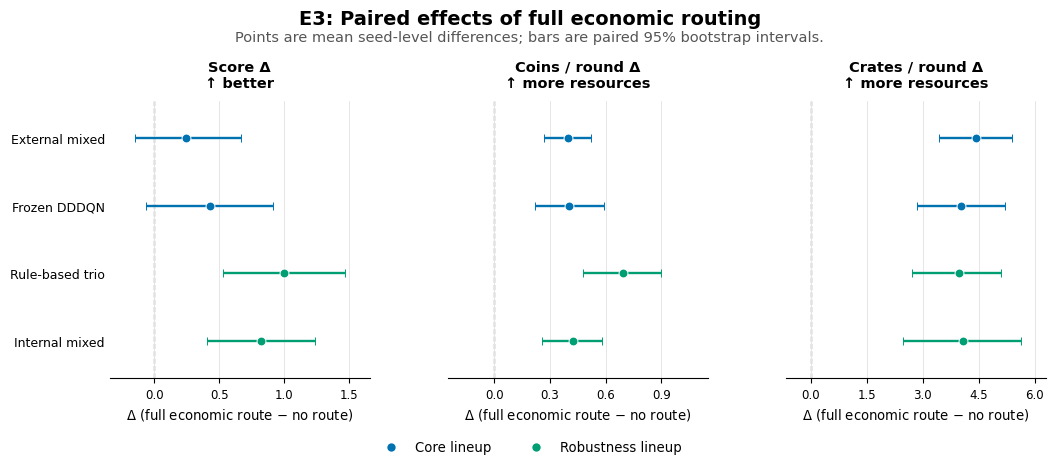

Saved: /Users/spnn/Documents/26SS-ScientificComputing/MachineLearningEssentials/final/MLE_project_bomberman_2026/results/e3_economic_routing/figure7_e3_paired_economic_effects.png
Saved: /Users/spnn/Documents/26SS-ScientificComputing/MachineLearningEssentials/final/MLE_project_bomberman_2026/results/e3_economic_routing/figure7_e3_paired_economic_effects.pdf


In [2]:
# Reproduce Figure 7 directly from the E3 paired-bootstrap results.
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

project_root = Path('..').resolve()
main_summary_path = project_root / 'results/e3_economic_routing/summary.json'
extension_summary_path = project_root / 'results/e3_economic_routing_extension/summary.json'
figure_png = project_root / 'results/e3_economic_routing/figure7_e3_paired_economic_effects.png'
figure_pdf = project_root / 'results/e3_economic_routing/figure7_e3_paired_economic_effects.pdf'

e3_main = json.loads(main_summary_path.read_text())
e3_extension = json.loads(extension_summary_path.read_text())
paired_bootstrap = e3_main['paired_bootstrap'] + e3_extension['paired_bootstrap']

lineups = (
    ('external_mixed', 'External mixed', '#0072B2', 'Core'),
    ('frozen_dddqn', 'Frozen DDDQN', '#0072B2', 'Core'),
    ('rule3', 'Rule-based trio', '#009E73', 'Robustness'),
    ('internal_mixed', 'Internal mixed', '#009E73', 'Robustness'),
)
metrics = (
    ('score', 'Score Δ', '↑ better'),
    ('coins', 'Coins / round Δ', '↑ more resources'),
    ('crates', 'Crates / round Δ', '↑ more resources'),
)
contrast = 'full_economic_route-no_economic_route'

def paired_effect(lineup, metric):
    row = next(
        item for item in paired_bootstrap
        if item['lineup'] == lineup
        and item['contrast'] == contrast
        and item['metric'] == metric
    )
    return row['mean_difference'], row['ci_low'], row['ci_high']

def shared_limits(metric):
    values = [0.0]
    for lineup, *_ in lineups:
        values.extend(paired_effect(lineup, metric))
    span = max(values) - min(values)
    padding = max(span * 0.12, 0.10 if metric == 'score' else 0.25)
    return min(values) - padding, max(values) + padding

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9.5,
    'axes.titlesize': 10.5, 'axes.labelsize': 9.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 9.0,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})
fig, axes = plt.subplots(1, 3, figsize=(12, 4.7), constrained_layout=False)
y_positions = list(range(len(lineups)))[::-1]

for ax, (metric, title, direction) in zip(axes, metrics):
    ax.axvline(0, color='#8A8A8A', linewidth=1.0, linestyle='--', zorder=0)
    for y, (lineup, label, color, _) in zip(y_positions, lineups):
        estimate, low, high = paired_effect(lineup, metric)
        ax.errorbar(
            estimate, y,
            xerr=[[estimate - low], [high - estimate]],
            fmt='o', markersize=6.4,
            markerfacecolor=color, markeredgecolor='white', markeredgewidth=0.7,
            ecolor=color, elinewidth=1.7, capsize=3.0, capthick=1.2, zorder=3,
        )
    ax.set_xlim(*shared_limits(metric))
    ax.set_ylim(-0.55, len(lineups) - 0.45)
    ax.set_yticks(y_positions)
    if ax is axes[0]:
        ax.set_yticklabels([item[1] for item in lineups])
    else:
        ax.set_yticklabels([])
        ax.tick_params(axis='y', length=0)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(axis='x', color='#E6E6E6', linewidth=0.7, zorder=0)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.set_xlabel(r'$\Delta$ (full economic route $-$ no route)')
    ax.set_title(f'{title}\n{direction}', pad=10, fontweight='semibold')

legend_handles = [
    Line2D([0], [0], marker='o', color=color, label=label, linestyle='none',
           markerfacecolor=color, markeredgecolor='white', markersize=7)
    for label, color in (('Core lineup', '#0072B2'), ('Robustness lineup', '#009E73'))
]
fig.legend(handles=legend_handles, loc='lower center', ncol=2, frameon=False,
           bbox_to_anchor=(0.55, 0.012), columnspacing=2.4)
fig.suptitle('E3: Paired effects of full economic routing',
             x=0.55, y=0.985, fontsize=14, fontweight='bold')
fig.text(0.55, 0.940,
         'Points are mean seed-level differences; bars are paired 95% bootstrap intervals.',
         ha='center', va='top', fontsize=10.5, color='#555555')
fig.subplots_adjust(left=0.20, right=0.98, top=0.79, bottom=0.20, wspace=0.30)

figure_png.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_png, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(figure_pdf, bbox_inches='tight', facecolor='white')
plt.show()

print(f'Saved: {figure_png}')
print(f'Saved: {figure_pdf}')
